# Flow-dependent heat transfer coefficients

By default the heat transfer coefficient between the fluid and the storage is a constant
parameter, `"Heat transfer coefficient [W.m-2.K-1]"`. In practice it depends on the flow, so a
value chosen at one flow rate does not hold at another. The option
`"heat transfer coefficient"` computes it instead from a Nusselt number correlation, with the
fluid properties from the fluid-property object and the geometry from the family:

- `"Gnielinski"` in the finned-tube models, for the flow inside the tubes;
- `"Wakao-Kaguei"` in the packed bed, for the flow around the capsules.

Every model outputs `"Heat transfer coefficient [W.m-2.K-1]"`; with a correlation it also
outputs the surface Reynolds, Prandtl and Nusselt numbers.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pybamm

import pytes

The Gnielinski law uses the laminar Nusselt number of a tube at a uniform wall temperature,
3.66, below a Reynolds number of 2300, the Gnielinski correlation above $10^4$, and a linear
interpolation in between.

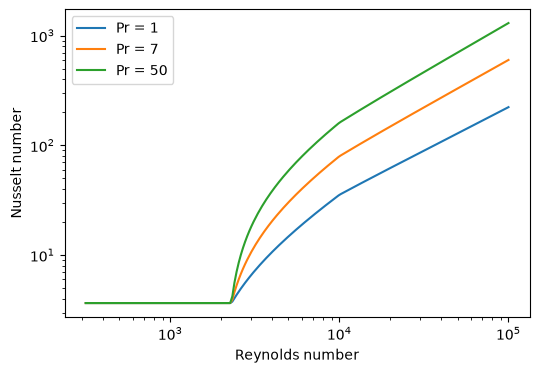

In [2]:
Re = np.logspace(2.5, 5, 200)
fig, ax = plt.subplots(figsize=(6, 4))
for Pr in (1, 7, 50):
    Nu = pytes.submodels.Gnielinski(1).nusselt(pybamm.Vector(Re), pybamm.Scalar(Pr))
    ax.loglog(Re, Nu.evaluate(), label=f"Pr = {Pr}")
ax.set_xlabel("Reynolds number")
ax.set_ylabel("Nusselt number")
ax.legend()
plt.show()

The default finned-tube battery runs at a Reynolds number of about 4200, in the transition,
where the correlation gives a coefficient about twice the default constant. Here the battery
is discharged at the default flow rate and at a quarter of it, which is laminar.

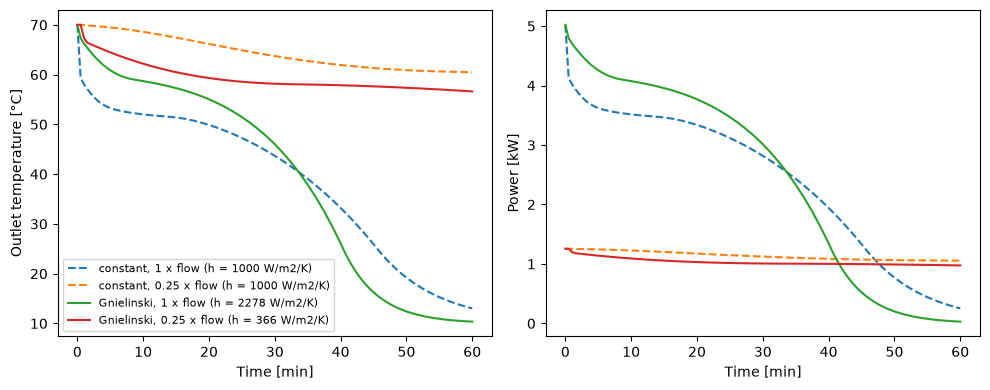

In [3]:
t = np.linspace(0, 3600, 121)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for option, style in [("constant", "--"), ("Gnielinski", "-")]:
    model = pytes.SharpFrontModel(options={"heat transfer coefficient": option})
    for factor in (1, 0.25):
        parameter_values = model.default_parameter_values
        parameter_values["Mass flow rate [kg.s-1]"] *= factor
        solution = pybamm.Simulation(model, parameter_values=parameter_values).solve(
            [0, t[-1]], t_interp=t
        )
        h = solution["Heat transfer coefficient [W.m-2.K-1]"].entries[0]
        label = f"{option}, {factor:g} x flow (h = {h:.0f} W/m2/K)"
        time = solution["Time [min]"].entries
        axes[0].plot(
            time, solution["Outlet temperature [degC]"].entries, style, label=label
        )
        axes[1].plot(time, solution["Power [kW]"].entries, style, label=label)
axes[0].set_ylabel("Outlet temperature [°C]")
axes[1].set_ylabel("Power [kW]")
for ax in axes:
    ax.set_xlabel("Time [min]")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In the packed bed of Nallusamy et al. (2007), the Wakao and Kaguei correlation gives about
150 W.m-2.K-1, against the constant 100 of the default set, and fits the measured fluid
temperature slightly better.

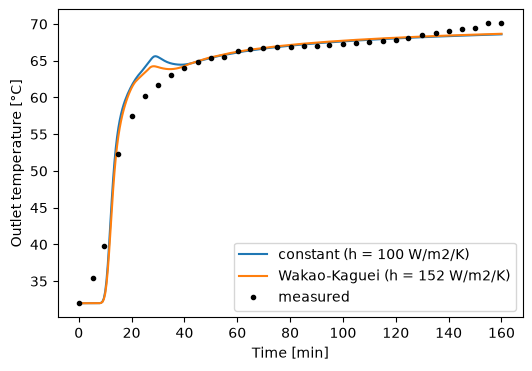

In [4]:
t_end = 160 * 60
t = np.linspace(0, t_end, 321)
t_data, T_data = np.loadtxt(
    "data/Nallusamy2007_HTF_1L.csv", delimiter=",", skiprows=1, unpack=True
)
fig, ax = plt.subplots(figsize=(6, 4))
for option in ("constant", "Wakao-Kaguei"):
    model = pytes.PackedBedModel(options={"heat transfer coefficient": option})
    solution = pybamm.Simulation(model).solve([0, t_end], t_interp=t)
    h = solution["Heat transfer coefficient [W.m-2.K-1]"].entries[0]
    ax.plot(
        solution["Time [min]"].entries,
        solution["Outlet temperature [degC]"].entries,
        label=f"{option} (h = {h:.0f} W/m2/K)",
    )
ax.plot(t_data, T_data, "ko", markersize=3, label="measured")
ax.set_xlabel("Time [min]")
ax.set_ylabel("Outlet temperature [°C]")
ax.legend()
plt.show()

Under an experiment that adjusts the flow rate, such as a constant power discharge, the
coefficient follows the flow.

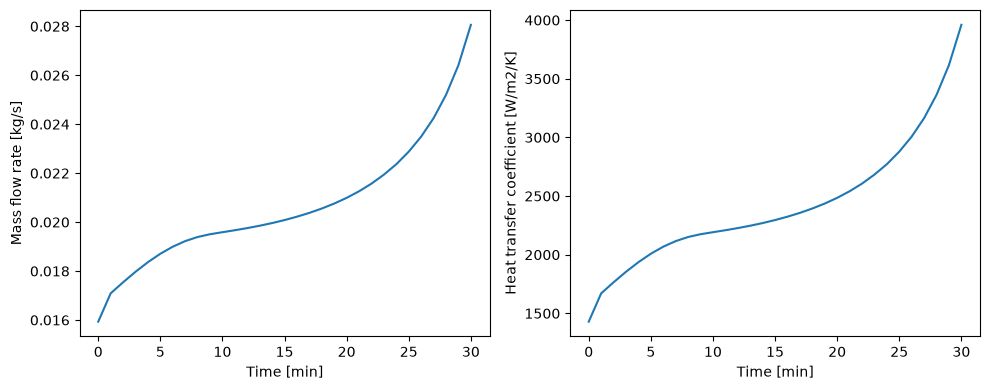

In [5]:
model = pytes.SharpFrontModel(options={"heat transfer coefficient": "Gnielinski"})
experiment = pytes.experiments.Experiment(
    [
        pytes.experiments.step.ConstantPower(
            4000, inlet_temperature=283.15, duration=1800
        )
    ]
)
solution = pytes.experiments.run_experiment(model, experiment)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
time = solution["Time [min]"].entries
axes[0].plot(time, solution["Mass flow rate [kg.s-1]"].entries)
axes[0].set_ylabel("Mass flow rate [kg/s]")
axes[1].plot(time, solution["Heat transfer coefficient [W.m-2.K-1]"].entries)
axes[1].set_ylabel("Heat transfer coefficient [W/m2/K]")
for ax in axes:
    ax.set_xlabel("Time [min]")
plt.tight_layout()
plt.show()

## A correlation of your own

A correlation is only its Nusselt number: the family supplies the geometry (here the tube
diameter, and the mean velocity in a tube) and the fluid-property object the properties.
`register_correlation` adds a function of the Reynolds and Prandtl numbers, as PyBaMM
symbols, as a value of the option for the models of its flow geometry, `"tube"` or
`"packed bed"`. PyTES adds its own correlations the same way. `replace=True` lets the cell
run again.

Here the Dittus-Boelter correlation, for a fluid being heated, is compared with Gnielinski
at four times the default flow, where both apply ($Re > 10^4$).
`conformance.check_model` (in `pytes.conformance`) runs the contract on the model, energy conservation
included, and returns its solution.

In [6]:
from pytes import conformance


def dittus_boelter(Re, Pr):
    return 0.023 * Re**0.8 * Pr**0.4


pytes.submodels.register_correlation(
    "Dittus-Boelter", dittus_boelter, flow="tube", replace=True
)
print(pytes.SharpFrontModel.allowed_options["heat transfer coefficient"])

for option in ("Gnielinski", "Dittus-Boelter"):
    model = pytes.SharpFrontModel(options={"heat transfer coefficient": option})
    parameter_values = model.default_parameter_values
    parameter_values["Mass flow rate [kg.s-1]"] *= 4
    solution = conformance.check_model(model, parameter_values)
    Re = solution["Surface Reynolds number"].entries[0]
    h = solution["Heat transfer coefficient [W.m-2.K-1]"].entries[0]
    print(f"{option}: Re = {Re:.0f}, h = {h:.0f} W/m2/K")

HeatTransferCoefficientOptions('tube'): ['constant', 'Gnielinski', 'Dittus-Boelter']


Gnielinski: Re = 16977, h = 12813 W/m2/K


Dittus-Boelter: Re = 16977, h = 12106 W/m2/K


A law that is not a Nusselt correlation, such as a wall resistance in series or a
nonlinear law, goes to the coupling through the composition API instead (see
`composing_models.ipynb`).